# Разведочный анализ датасета

In [ ]:

import re
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

ID2LABEL = {0: "joy", 1: "sadness", 2: "surprise", 3: "fear", 4: "anger"}
EMOTIONS = list(ID2LABEL.values())

splits = {
    "train": "enriched/train-00000-of-00001.parquet",
    "test": "enriched/test-00000-of-00001.parquet",
}
base = "hf://datasets/sagteam/cedr_v1/"
train = pd.read_parquet(base + splits["train"])
test = pd.read_parquet(base + splits["test"])
train["split"], test["split"] = "train", "test"
df = pd.concat([train, test], ignore_index=True)

## 1. Общая информация

In [7]:
print("train:", train.shape, "| test:", test.shape)
print(df.dtypes)
print("\nПропуски:\n", df.isna().sum())
df.head()

train: (7528, 5) | test: (1882, 5)
text            str
labels       object
source          str
sentences    object
split           str
dtype: object

Пропуски:
 text         0
labels       0
source       0
sentences    0
split        0
dtype: int64


,text,labels,source,sentences,split
0,Суровый гималайский медведь .,[],lj,"[[{'forma': 'Суровый', 'lemma': 'суровый'}, {'forma': 'гималайский', 'lemma': 'гималайский'}, {'forma': 'медведь', '...",train
1,"Так, обнаружено несколько проблем с дисплеем (выгорание, странные зеленые полосы), дефекты динамика и некорректная р...",[],lenta,"[[{'forma': 'Так', 'lemma': 'так'}, {'forma': ',', 'lemma': ','}, {'forma': 'обнаружено', 'lemma': 'обнаружить'}, {'...",train
2,"У меня остается только один вопрос - является ли этот приступ отчаяния ( а точнее приступ удивления , почему мне не ...",[2],lj,"[[{'forma': 'У', 'lemma': 'у'}, {'forma': 'меня', 'lemma': 'я'}, {'forma': 'остается', 'lemma': 'оставаться'}, {'for...",train
3,Забавно как люди в возрасте удивляются входящим звонкам на мобильник),[0],twitter,"[[{'forma': 'Забавно', 'lemma': 'Забавно'}, {'forma': 'как', 'lemma': 'как'}, {'forma': 'люди', 'lemma': 'человек'},...",train
4,"Издание The Register отмечает, что у владельцев гаджетов пока нет повода для паники из-за уязвимости батареи, потому...",[],lenta,"[[{'forma': 'Издание', 'lemma': 'издание'}, {'forma': 'The', 'lemma': 'The'}, {'forma': 'Register', 'lemma': 'Regist...",train


In [ ]:
# labels - список id эмоций (может быть пустым = нет эмоции)
df["labels"] = df["labels"].apply(lambda x: sorted(int(i) for i in x))
df["n_labels"] = df["labels"].apply(len)

# one-hot колонки по эмоциям
for i, name in ID2LABEL.items():
    df[name] = df["labels"].apply(lambda l: int(i in l))
df["no_emotion"] = (df["n_labels"] == 0).astype(int)

## 2. Источники и сплиты

In [9]:
print(pd.crosstab(df["source"], df["split"], margins=True))
print()
print(pd.crosstab(df["source"], df["split"], normalize="columns").round(3))

split    test  train   All
source                    
lenta     556   2295  2851
lj        623   2446  3069
twitter   703   2787  3490
All      1882   7528  9410

split     test  train
source               
lenta    0.295  0.305
lj       0.331  0.325
twitter  0.374  0.370


## 3. Распределение эмоций

split       test  train
joy          353   1569
sadness      379   1417
surprise     170    607
fear         141    589
anger        125    411
no_emotion   734   3043 

% от примеров:
 split       test  train
joy         18.8   20.8
sadness     20.1   18.8
surprise     9.0    8.1
fear         7.5    7.8
anger        6.6    5.5
no_emotion  39.0   40.4


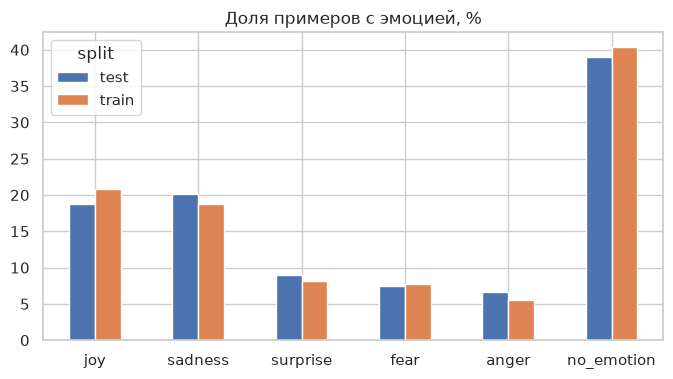

In [10]:
cnt = df.groupby("split")[EMOTIONS + ["no_emotion"]].sum().T
cnt_pct = (df.groupby("split")[EMOTIONS + ["no_emotion"]].mean().T * 100).round(1)
print(cnt, "\n\n% от примеров:\n", cnt_pct)

cnt_pct.plot.bar(figsize=(8, 4), title="Доля примеров с эмоцией, %")
plt.xticks(rotation=0)
plt.show()

n_labels
0    3777
1    5506
2     126
3       1
Name: count, dtype: int64

Среднее число меток (Label Cardinality): 0.612
Label Density: 0.122


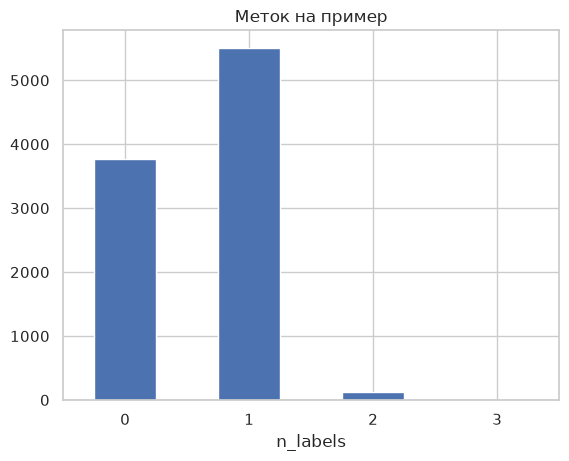

In [ ]:
# Количество меток на пример
print(df["n_labels"].value_counts().sort_index())
print("\nСреднее число меток (Label Cardinality):", df["n_labels"].mean().round(3))
print("Label Density:", (df["n_labels"].mean() / len(EMOTIONS)).round(3))

df["n_labels"].value_counts().sort_index().plot.bar(title="Меток на пример")
plt.xticks(rotation=0)
plt.show()

          joy  sadness  surprise  fear  anger  no_emotion
source                                                   
lenta     6.5      3.1       6.7   4.0    3.9        75.9
lj       14.0      9.7      12.7   8.6    7.5        48.6
twitter  37.4     40.4       5.6  10.1    5.6         3.5


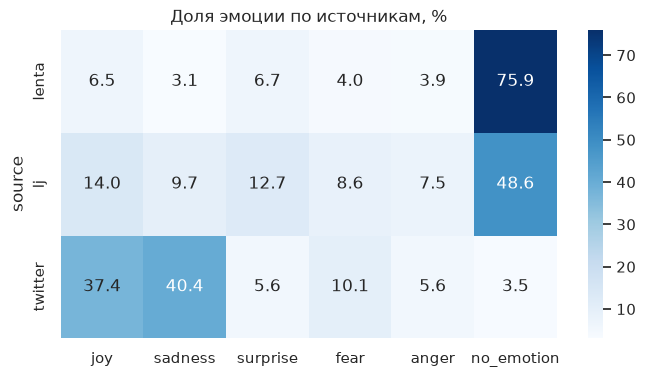

In [12]:
# Эмоции по источникам
by_src = df.groupby("source")[EMOTIONS + ["no_emotion"]].mean().mul(100).round(1)
print(by_src)

plt.figure(figsize=(8, 4))
sns.heatmap(by_src, annot=True, fmt=".1f", cmap="Blues")
plt.title("Доля эмоции по источникам, %")
plt.show()

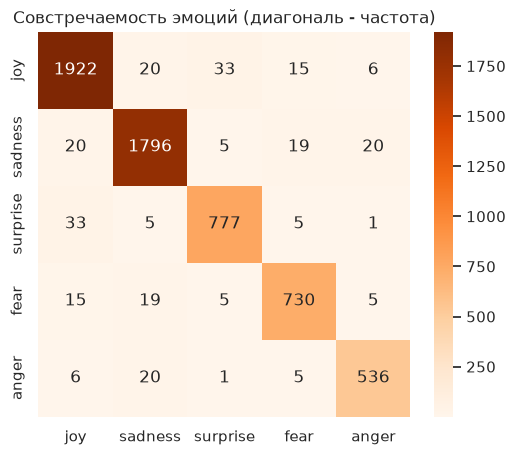

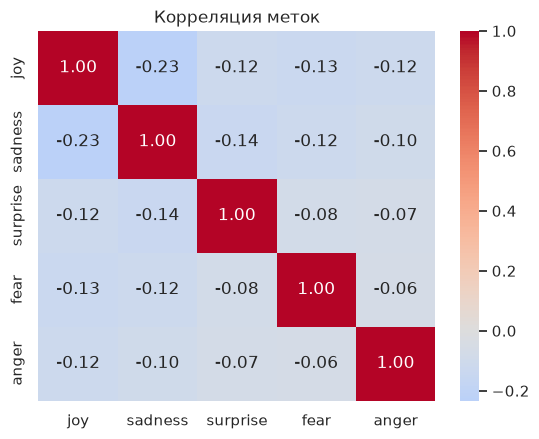

labels
none                3777
joy                 1849
sadness             1733
surprise             733
fear                 686
anger                505
joy+surprise          33
sadness+anger         19
sadness+fear          19
joy+sadness           19
joy+fear              15
sadness+surprise       5
fear+anger             5
surprise+fear          5
joy+anger              5
Name: count, dtype: int64


In [13]:
# Совстречаемость эмоций
co = pd.DataFrame(0, index=EMOTIONS, columns=EMOTIONS)
for l in df["labels"]:
    for a, b in combinations(l, 2):
        co.loc[ID2LABEL[a], ID2LABEL[b]] += 1
        co.loc[ID2LABEL[b], ID2LABEL[a]] += 1
for e in EMOTIONS:
    co.loc[e, e] = df[e].sum()

plt.figure(figsize=(6, 5))
sns.heatmap(co, annot=True, fmt="d", cmap="Oranges")
plt.title("Совстречаемость эмоций (диагональ - частота)")
plt.show()

# Корреляция между эмоциями
sns.heatmap(df[EMOTIONS].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляция меток")
plt.show()

# Топ-комбинаций меток
combo = df["labels"].apply(lambda l: "+".join(ID2LABEL[i] for i in l) or "none")
print(combo.value_counts().head(15))

## 4. Длина текстов

       n_chars  n_words
count   9410.0   9410.0
mean      92.3     14.8
std       48.6      7.9
min        5.0      1.0
25%       54.0      9.0
50%       85.0     14.0
75%      124.0     19.0
max      280.0     51.0


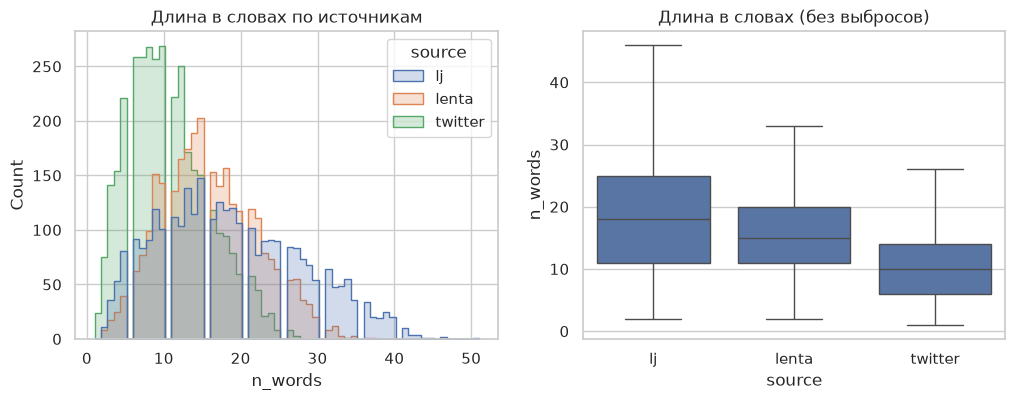

n_labels
0    17.3
1    13.0
2    15.0
3    17.0
Name: n_words, dtype: float64
          count  mean  std  min   25%   50%   75%   max
source                                                 
lenta    2851.0  15.8  6.3  2.0  11.0  15.0  20.0  37.0
lj       3069.0  18.7  9.3  2.0  11.0  18.0  25.0  51.0
twitter  3490.0  10.5  5.2  1.0   6.0  10.0  14.0  27.0

Самые короткие:
        text   source labels
5554   ужас!  twitter    [3]
6974   Горе!  twitter    [1]
7518   Злой.  twitter    [4]
1442  Ужас .       lj    [3]
4080  чудно!  twitter    [0]

Самые длинные:
                                                                                                                         text  \
211   не знаю пивасик,не знаю :)_x005F_x005F_x005F_x005F_x005F_x005F_x005F_x005F_x000D_\nтак обходиться жизнь :D_x005F_x00...   
3283  Телевизионный критик издания The New Yorker Эмили Нуссбаум (Emily Nussbaum) вспомнила о казусе в магазине: «Пошла в ...   
3602  Мем под названием «неверный парень» приоб

In [ ]:
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str.split().str.len()

print(df[["n_chars", "n_words"]].describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df, x="n_words", hue="source", bins=60, ax=ax[0], element="step")
ax[0].set_title("Длина в словах по источникам")
sns.boxplot(data=df, x="source", y="n_words", ax=ax[1], showfliers=False)
ax[1].set_title("Длина в словах (без выбросов)")
plt.show()

# Длина число эмоций / эмоция
print(df.groupby("n_labels")["n_words"].mean().round(1))
print(df.groupby("source")["n_words"].describe().round(1))

# Выбросы
print("\nСамые короткие:")
print(df.nsmallest(5, "n_chars")[["text", "source", "labels"]])
print("\nСамые длинные:")
print(df.nlargest(3, "n_chars")[["text", "source", "n_words"]])

## 5. Качество данных: дубликаты, пустые, особенности текста

In [15]:
print("Полные дубликаты текста:", df["text"].duplicated().sum())
dups = df[df["text"].duplicated(keep=False)].sort_values("text")
print(dups[["text", "labels", "source", "split"]].head(10))

# Одинаковый текст с разными метками
conflict = df.groupby("text")["labels"].apply(lambda s: len(set(map(tuple, s))) > 1)
print("Тексты с конфликтующими метками:", conflict.sum())

# Пересечение train/test (утечка)
leak = set(train["text"]) & set(test["text"])
print("Тексты, одновременно в train и test:", len(leak))

Полные дубликаты текста: 42
                                                               text labels  \
462   Больше ада и странных новостей в Telegram-канале «Лента дна».     []   
500   Больше ада и странных новостей в Telegram-канале «Лента дна».     []   
2009  Больше ада и странных новостей в Telegram-канале «Лента дна».     []   
3536  Больше ада и странных новостей в Telegram-канале «Лента дна».     []   
3611  Больше ада и странных новостей в Telegram-канале «Лента дна».     []   
3680  Больше ада и странных новостей в Telegram-канале «Лента дна».     []   
4052  Больше ада и странных новостей в Telegram-канале «Лента дна».     []   
4215  Больше ада и странных новостей в Telegram-канале «Лента дна».     []   
6180  Больше ада и странных новостей в Telegram-канале «Лента дна».     []   
6265  Больше ада и странных новостей в Telegram-канале «Лента дна».     []   

     source  split  
462   lenta  train  
500   lenta  train  
2009  lenta  train  
3536  lenta  train  
3611  le

## 7. Примеры текстов

In [25]:
for e in EMOTIONS + ["no_emotion"]:
    print(f"\n=== {e} ===")
    sample = df[df[e] == 1].sample(4, random_state=42)
    for _, r in sample.iterrows():
        print(f"[{r['source']}] {r['text']}  -> {[ID2LABEL[i] for i in r['labels']]}")


=== joy ===
[lenta] Они обрадовались друг другу и начали вспоминать прошлое.  -> ['joy']
[twitter] Одним словом диссреспект  за жестокое обращение с животными в гифках :D и респект коту, у него явно есть яйца, он мужик  -> ['joy']
[twitter] Родители заказали суши,чтобы порадовать меня,а то температура и очень плохо( люблю вас☺️❤️  -> ['joy', 'sadness']
[lj] Алина заулыбалась еще шире ,– почему-то я даже не нахожу это странным , что кот может разговаривать .  -> ['joy']

=== sadness ===
[twitter] так хочется,чтобы всех все устраивало,чтобы люди не были такими злыми к близким и близким друзьям...:(((  -> ['sadness']
[lj] К сожалению , чехи сейчас откровенно слабы .  -> ['sadness']
[twitter] Окончательный вердикт- ангина :( Знали бы вы как это ужасно  -> ['sadness']
[lj] Единственный снегоочиститель , имевшийся на нашем участке фронты не смог проломить ледяные стены , несмотря на яростные усилия .  -> ['sadness']

=== surprise ===
[twitter] Человек, который изо дня в день продолжает меня